# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Camello, Zack Kenshin)_:
- _Student No._: 2024-08825
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

# Report figure
### Function 1: $ y = \sqrt{9-4x^2}, x=0, x=3/2 $

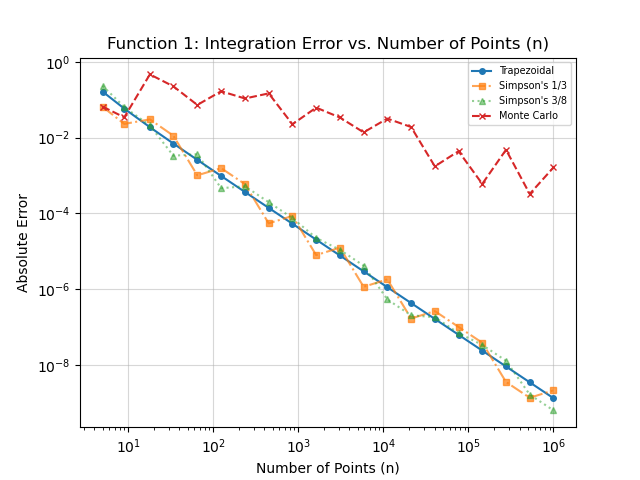

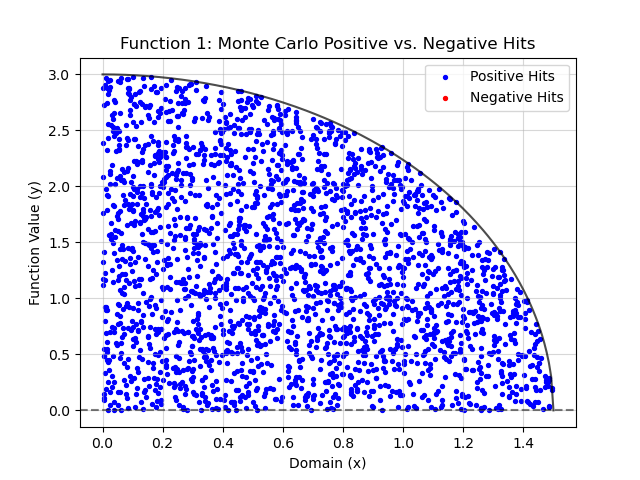

### Function 2: $ y = -x^2 + 1, x=-2, x=2 $

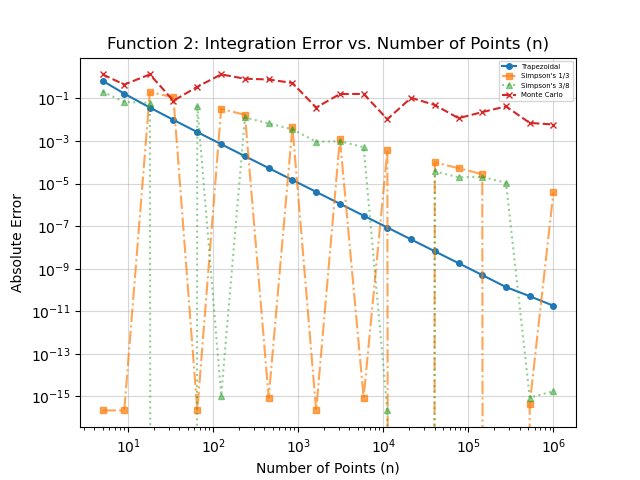

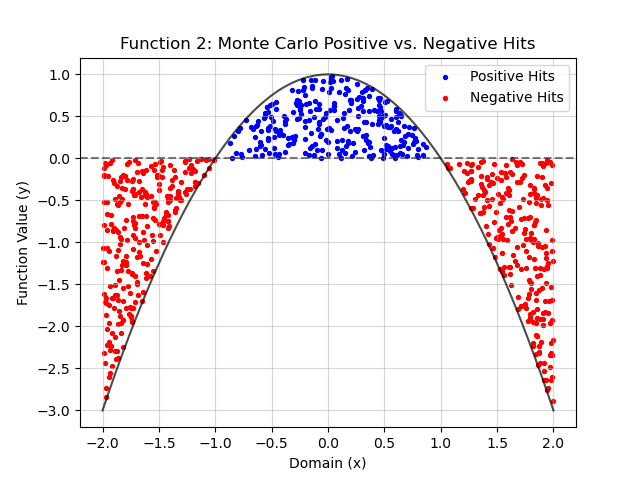

### Function 3: $ y = \sqrt{x}\cos{x}, x=0, x=\pi $

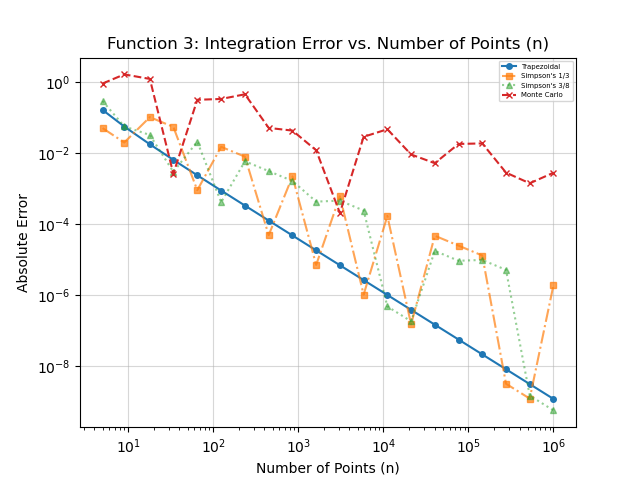

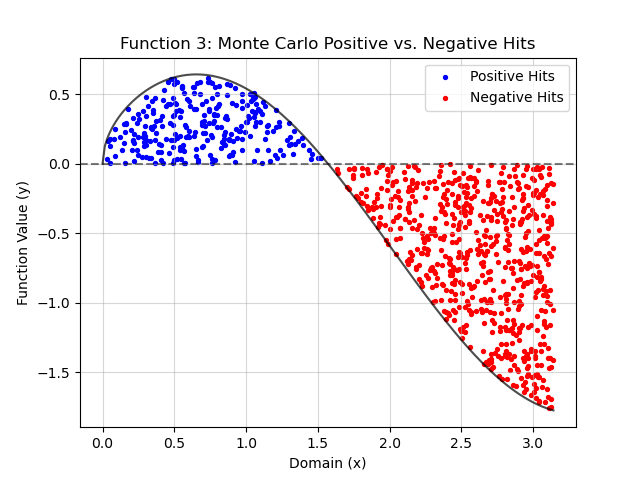

# Report discussion
1. Explain the figures.

The log-log absolute error plots illustrate the convergence behavior of each numerical integration method as the sample size increases. Overall, the Trapezoidal rule acts as a stable baseline across all three test functions, yielding smooth and consistent reduction in errors across all trials. Similarly, Simpson’s 1/3 and 3/8 methods exhibit a consistent trend of lower errors as n increases, but achieve lower error magnitudes than the Trapezoidal rule. Notably, for the second test function, the absolute error of both Simpson's methods drop dramatically down even at small n values. This is because in this trial, the method is able to achieve polynomial exactness. Across all trials, the Monte Carlo method exhibited erratic behavior due to its inherent randomized sampling nature. 

Furthermore, the Monte Carlo Hit-or-Miss scatter plots map individual sample coordinates within the bounding box and categorize them based on their sign relative to the x-axis. Points that fall under the curve and are above the x-axis are categorized as positive hits and colored blue, while points below the x-axis and above the curve are categorized as negative hits and colored red. Mathematically, the ratio of these hits relative to the total number of sampled points, multiplied by the area of our bounding box, determines the net signed integral.

2. Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?

We can obtain an integration value using the Monte Carlo method because of basic spatial probability. By randomly scattering a large number of points across a known rectangular area surrounding a function, the proportion of points that land under the curve directly corresponds to the fraction of area occupied by the function. Multiplying this ratio by the total area of the bounding box gives us an estimate of the integral. As the number of random points increases, the estimated area steadily approaches the true value.

Specifically, Newton-Cotes methods are much more appropriate when integrating smooth and continuous functions because they rely on simple grid spacing and polynomial fitting. This allows them to achieve high accuracy even at low sample sizes. However, these methods become impractical for higher-dimensional integrals or functions with complex geometries. In those cases, the Monte Carlo method is far more suitable, as it can handle complex shapes just as easily through its random sampling.

# Other comments

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

Report Figures (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

Report discussion: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [122]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

def f1(x):
    return np.sqrt(9 - (4 * (x ** 2)))

def f2(x):
    return -x**2 + 1

def f3(x):
    return np.cos(x) * np.sqrt(x)

def trapezoidal(func, left, right, n):
    trap_x = np.linspace(left, right, n)
    trap_y = func(trap_x)
    trap_dx = trap_x[1] - trap_x[0]

    trap_total = 0
    trap_signed = 0
    for i in range(n-1):
        trap_total += 0.5 * (np.abs(trap_y[i]) + np.abs(trap_y[i+1])) * trap_dx # Takes total area WITHOUT taking into account negative ones
        trap_signed +=  0.5 * (trap_y[i] + trap_y[i+1]) * trap_dx # Takes area while considering negatives

    return trap_total, trap_signed

def montecarlo(func, left, right, n):
    test_x = np.linspace(left, right, n)
    test_y = func(test_x)

    ymin = min(0, np.min(test_y)) # Checks if our min value is either 0 or something else
    ymax = max(0, np.max(test_y)) # Checks if our max value is either some number or just 0

    bounds = (right - left) * (ymax - ymin)

    random_x = np.random.uniform(left, right, n) # Generates our random x values
    random_y = np.random.uniform(ymin, ymax, n) # Generates our random y values

    curve = func(random_x) # Determines the corresponding y value to our random x values

    pos_points = (random_y > 0) & (random_y <= curve) # Checks whether a y point is above the x-axis and below the curve
    neg_points = (random_y < 0) & (random_y >= curve) # Checks whether a y point is below the x-axis and above the curve

    num_pos = np.sum(pos_points)
    num_neg = np.sum(neg_points)

    monte_total = bounds * (num_pos + num_neg) / n # Formula for area considering only magnitude of areas
    monte_signed = bounds * (num_pos - num_neg) / n # Formula for area considering the negative effect of negative locations
    
    return monte_total, monte_signed, random_x, random_y, pos_points, neg_points

def simpson_13(func, left, right, n):
    if n % 2 == 0: # Ensures our points are always odd
        n += 1
    h = (right - left) / (n - 1)
    xs = left + np.arange(n) * h
    cs = 2 * np.ones(n) # Creates n amount of 2s
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1 # Replaces every 2 steps starting from 2nd number with a 4, replaces first and last with 1
    contribs = cs * func(xs)

    simpson13_total = (h/3) * np.sum(cs * np.abs(func(xs))) # Formula considering area only using magnitude
    simpson13_signed = (h/3) * np.sum(contribs) # Formula considering the effects of negative areas
    
    return simpson13_total, simpson13_signed

def simpson_38(func, left, right, n):
    while (n - 1) % 3 != 0: # Ensures it always stays a multiple of 3
        n += 1
    h = (right - left) / (n - 1)
    xs = left + np.arange(n) * h
    cs = 3 * np.ones(n) # Creates n amount of 3s
    cs[3::3] = 2; cs[0] = 1; cs[-1] = 1 # Replaces every 3 steps starting from 4th number with a 2, and replaces first and last with a 1
    contribs = cs * func(xs)

    simpson38_total = (3/8) * h * np.sum(cs * np.abs(func(xs)))
    simpson38_signed = (3/8) * h * np.sum(contribs)
    
    return simpson38_total, simpson38_signed

In [129]:
# Functions and Respective Bounds
func1 = f1, 0, 1.5
func2 = f2, -2, 2
func3 = f3, 0, np.pi

current = func3 # Edit depending on which one we want to look at

func, left, right = current
axis = np.logspace(0.7, 6, 20, dtype = int) # Sets our axis in logspace
actual_val = integrate.quad(func, left, right)[0] # Calculates the actual integral values directly (which is a SIGNED value)

# Solving for absolute errors
trapezoid_error = [np.abs(trapezoidal(func, left, right, n)[1] - actual_val) for n in axis]
monte_error = [np.abs(montecarlo(func, left, right, n)[1] - actual_val) for n in axis]
simpson13_error = [np.abs(simpson_13(func, left, right, n)[1] - actual_val) for n in axis]
simpson38_error = [np.abs(simpson_38(func, left, right, n)[1] - actual_val) for n in axis]

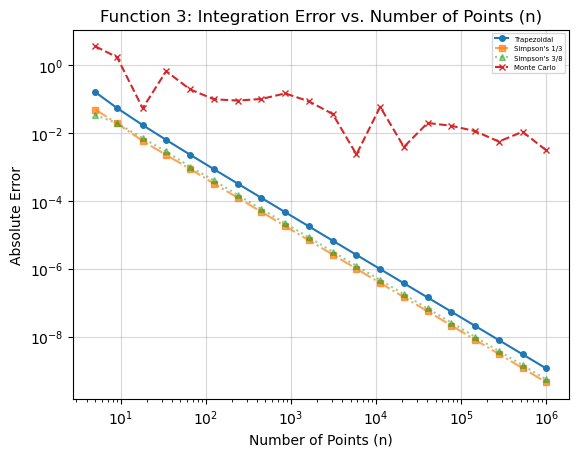

In [130]:
plt.figure()

plt.plot(axis, trapezoid_error, label = "Trapezoidal", marker = "o", markersize = 4)
plt.plot(axis, simpson13_error, label = "Simpson's 1/3", marker = "s", markersize = 4, linestyle = "-.", alpha = 0.7)
plt.plot(axis, simpson38_error, label = "Simpson's 3/8", marker = "^", markersize = 4, linestyle = ":", alpha = 0.5)
plt.plot(axis, monte_error, label = "Monte Carlo", marker = "x", markersize = 4, linestyle = "--")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Points (n)")
plt.ylabel("Absolute Error")
plt.title("Function 3: Integration Error vs. Number of Points (n)")
plt.grid(True, alpha=0.5)
plt.legend(loc = "upper right", fontsize = 5)
plt.savefig("Integration Error Function 3")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

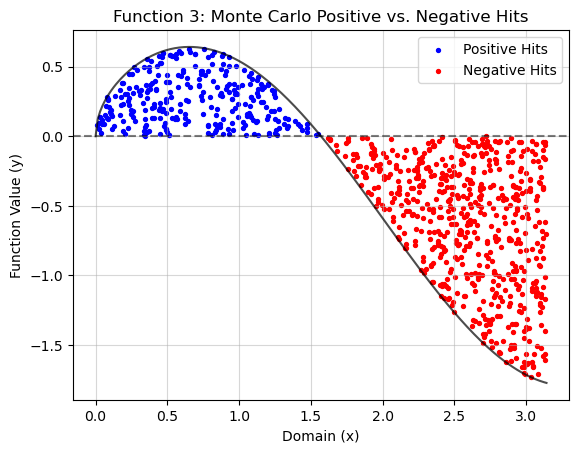

In [131]:
# Running Monte Carlo Integration for the graph
sim_n = 3000

_, _, random_x, random_y, pos_points, neg_points = montecarlo(*current, sim_n)

plt.figure()
plt.scatter(random_x[pos_points], random_y[pos_points], color = "blue", label = "Positive Hits", s = 8)
plt.scatter(random_x[neg_points], random_y[neg_points], color = "red", label = "Negative Hits", s = 8)

# Create the reference plot
sim_axis = np.linspace(left, right, 200)
plt.plot(sim_axis, func(sim_axis), color = "black", alpha = 0.7)
plt.xlabel("Domain (x)")
plt.ylabel("Function Value (y)")
plt.title("Function 3: Monte Carlo Positive vs. Negative Hits")
plt.axhline(y = 0, linestyle = "--", alpha = 0.5, color = "black")
plt.legend(loc = "upper right")
plt.grid(True, alpha = 0.5)
plt.savefig("Monte Carlo Function 3")
plt.show

### Code Summary
The algorithm above simply makes the methods, evaluates the functions using them and determines the absolute error in comparison to direct integration an